
## Volatility Misspecification

Experiment examines how incorrect volatility assumptions affect discrete delta-hedging performance.

Implied volatility fixed at 20% for option pricing and delta calculations, while stock prices are simulated using varying realised volatilities. Monthly, weekly and daily rebalancing are compared without transaction costs.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

In [2]:
def calculate_d1_d2(S, K, T, r, sigma):

    d1 = (np.log(S/K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)

    return d1,d2

def black_scholes_price(S, K, T, r, sigma):  

    d1, d2 = calculate_d1_d2(S, K, T, r, sigma)

    C = S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    P = K * np.exp(-r * T) * norm.cdf(-d2) - S * norm.cdf(-d1)

    return C,P

In [3]:
S0 = 100
K = 100
T = 1
r = 0.05
rng = np.random.default_rng(4)

In [4]:
M = 50000
batch_size = 10000

sigma_imp = 0.20
sigma_reals = np.linspace(0.10, 0.40, 52)

n_values = [12,52,252]

option_premium, _ = black_scholes_price(S0, K, T, r, sigma_imp)

results = [[[], []] for _ in sigma_reals]


for n in n_values:

    t_array = np.linspace(0, T, n + 1)
    delta_t = T / n
    tau = T - t_array[:-1]

    interest = np.exp(r * tau[1:])

    stats = [[0.0,0.0] for _ in sigma_reals]


    for start in range(0, M, batch_size):

        batch_M = min(batch_size, M - start)

        randoms = rng.normal(0, np.sqrt(delta_t), size=(batch_M, n))
        
        brownian = np.zeros((batch_M, n + 1))
        np.cumsum(randoms, axis = 1, out = brownian[:, 1:])


        for i, sigma_real in enumerate(sigma_reals):

            drift = (r - 0.5 * sigma_real ** 2) * t_array
            prices = S0 * np.exp(drift + sigma_real * brownian)

            d1, _ = calculate_d1_d2(prices[:, :-1], K, tau, r, sigma_imp)
            delta = norm.cdf(d1)

            delta_change = np.diff(delta, axis=1)
            rebalance_cashflows = delta_change * prices[:, 1:-1]

            total_rebalance = np.sum(rebalance_cashflows * interest, axis = 1)

            initial_cash = option_premium - S0 * delta[:, 0]
            terminal_cash = initial_cash * np.exp(r * T) - total_rebalance

            portfolio_value = terminal_cash + prices[:, -1] * delta[:, -1]
            call_payoff = np.maximum(prices[:, -1] - K, 0)

            error = portfolio_value - call_payoff

            stats[i][0] += np.sum(error)
            stats[i][1] += np.sum(error ** 2)


    for i in range(len(stats)):

        mean = stats[i][0] / M
        mean_sq = stats[i][1] / M
        std = np.sqrt(mean_sq - mean ** 2)

        results[i][0].append(mean)
        results[i][1].append(std)
        



### Mean Hedging P&L

Mean terminal P&L is evaluated across realised volatilities, holding implied volatility fixed.

For a short call, realised volatility exceeding implied volatility is expected to produce negative P&L, while lower realised volatility produces positive P&L.

Under the risk-neutral model:

$$
\mathbb{E}[\varepsilon_T]
= e^{rT}\left[C_{\mathrm{BS}}(\sigma_{\mathrm{imp}})-C_{\mathrm{BS}}(\sigma_{\mathrm{real}})\right]
$$


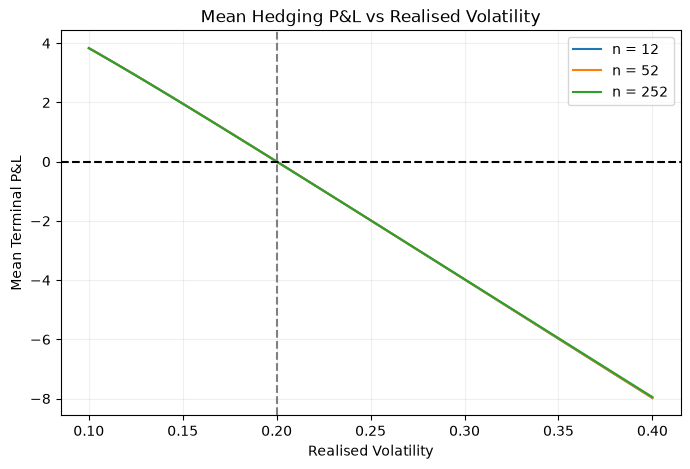

In [5]:
plt.figure(figsize=(8, 5))

for i in range(len(n_values)):
    plt.plot(sigma_reals, [results[j][0][i] for j in range(len(sigma_reals))],
             label=f"n = {n_values[i]}")

plt.axhline(0, color="black", linestyle="--")
plt.axvline(sigma_imp, color="grey", linestyle="--")

plt.xlabel("Realised Volatility")
plt.ylabel("Mean Terminal P&L")
plt.title("Mean Hedging P&L vs Realised Volatility")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


## Hedging P&L Dispersion

Standard Deviation of terminal P&L is compared across realised volatilities and rebalancing frequencies.

More frequent rebalancing reduces discretisation error, but cannot eliminate the effects of volatility misspecification.


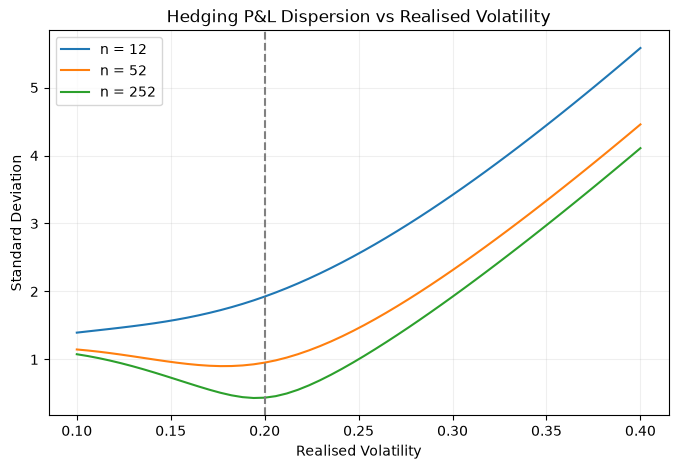

In [6]:
plt.figure(figsize=(8, 5))

for i in range(len(n_values)):
    plt.plot(sigma_reals, [results[j][1][i] for j in range(len(sigma_reals))],
             label=f"n = {n_values[i]}")

plt.axvline(sigma_imp, color="grey", linestyle="--")

plt.xlabel("Realised Volatility")
plt.ylabel("Standard Deviation")
plt.title("Hedging P&L Dispersion vs Realised Volatility")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

In [7]:
for sigma in [0.10, 0.20, 0.30]:
    j = np.argmin(np.abs(sigma_reals - sigma))

    print(f"\nRealised Volatility: {sigma_reals[j]:.1%}")

    for i, n in enumerate(n_values):
        mean = results[j][0][i]
        std = results[j][1][i]

        print(f"n = {n}: Mean = {mean:.3f}, Std = {std:.3f}")


Realised Volatility: 10.0%
n = 12: Mean = 3.838, Std = 1.394
n = 52: Mean = 3.834, Std = 1.146
n = 252: Mean = 3.832, Std = 1.076

Realised Volatility: 20.0%
n = 12: Mean = 0.007, Std = 1.925
n = 52: Mean = 0.004, Std = 0.953
n = 252: Mean = 0.001, Std = 0.437

Realised Volatility: 30.0%
n = 12: Mean = -3.979, Std = 3.421
n = 52: Mean = -3.976, Std = 2.314
n = 252: Mean = -3.968, Std = 1.923



### Results

Mean P&L is approximately zero when implied and realised volatility agree, becoming positive or negative as realised volatility moves below or above 20%.

The mean P&L curves nearly overlap across rebalancing frequencies, indicating that more frequent hedging does not remove systematic volatility-related P&L.

Daily rebalancing generally produces lower P&L dispersion, although substantial volatility misspecification still generates significant variability.
